# MNIST – Complete Unsupervised Learning Techniques

**Goal:** Explore MNIST images without using digit labels to train the models. We will apply dimensionality reduction, clustering, and anomaly detection, then evaluate clusters with internal metrics. Labels (when available) are used only at the end for optional comparison—not for training.

> **Important:** The notebook first looks for local MNIST IDX files (`train-images-idx3-ubyte`, etc.). If they are not found, it tries TensorFlow/Keras MNIST download. If neither is available, it uses scikit-learn's built-in handwritten-digits dataset only as a clearly labelled fallback so that the notebook can still be tested. For your actual MNIST assignment, place the four MNIST IDX files in the same folder as this notebook or ensure internet access for the Keras download.

## 1. Install / import libraries

Run the install cell only if a library is missing. Most packages are included in standard Anaconda/Jupyter environments.

In [1]:
# If required, uncomment and run:
# %pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

In [2]:
import os, gzip, struct, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
)
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.3.5
Pandas: 2.2.3


## 2. Load MNIST data

The MNIST training labels are deliberately kept separate. All unsupervised models below receive only image pixels (`X`), never `y`.

In [3]:
def read_idx_images(path):
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError(f"Invalid image IDX file: {path}")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(n, rows, cols)

def read_idx_labels(path):
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError(f"Invalid label IDX file: {path}")
        return np.frombuffer(f.read(), dtype=np.uint8)

def find_file(candidates):
    for name in candidates:
        if os.path.exists(name):
            return name
    return None

def load_mnist():
    image_candidates = [
        ["train-images-idx3-ubyte", "train-images-idx3-ubyte.gz"],
        ["train-images.idx3-ubyte", "train-images.idx3-ubyte.gz"]
    ]
    label_candidates = [
        ["train-labels-idx1-ubyte", "train-labels-idx1-ubyte.gz"],
        ["train-labels.idx1-ubyte", "train-labels.idx1-ubyte.gz"]
    ]
    image_path = next((find_file(c) for c in image_candidates if find_file(c)), None)
    label_path = next((find_file(c) for c in label_candidates if find_file(c)), None)

    if image_path and label_path:
        print("Loading local MNIST IDX files:", image_path, label_path)
        return read_idx_images(image_path), read_idx_labels(label_path), "Local MNIST IDX"

    try:
        from tensorflow.keras.datasets import mnist
        print("Local IDX files not found. Trying Keras MNIST download...")
        (x_train, y_train), _ = mnist.load_data()
        return x_train, y_train, "Keras MNIST"
    except Exception as e:
        print("Keras MNIST unavailable:", repr(e))
        print("Using sklearn digits fallback for notebook execution/testing.")
        from sklearn.datasets import load_digits
        ds = load_digits()
        # Resize 8x8 images to 28x28 for consistent plotting/flattening.
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        imgs = np.stack([zoom(im, (3.5, 3.5), order=1) for im in ds.images])
        imgs = np.clip(imgs / 16.0 * 255.0, 0, 255).astype(np.uint8)
        return imgs, ds.target.astype(np.uint8), "SKLEARN DIGITS FALLBACK (NOT MNIST)"

images, labels, DATA_SOURCE = load_mnist()
print("Dataset source:", DATA_SOURCE)
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Unique labels:", np.unique(labels))

Keras MNIST unavailable: ModuleNotFoundError("No module named 'tensorflow'")
Using sklearn digits fallback for notebook execution/testing.
Dataset source: SKLEARN DIGITS FALLBACK (NOT MNIST)
Images shape: (1797, 28, 28)
Labels shape: (1797,)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


## 3. Inspect and visualize the data

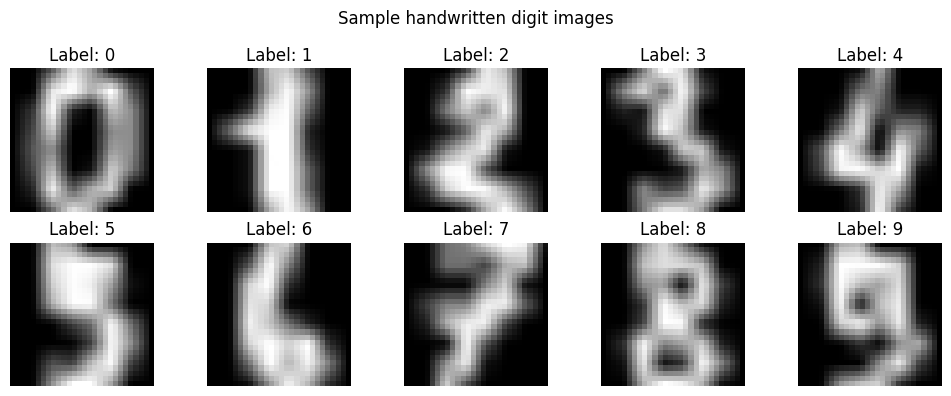

Pixel minimum: 0
Pixel maximum: 255
Image dimensions: (28, 28) pixels


In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Label: {labels[i]}")
    ax.axis("off")
plt.suptitle("Sample handwritten digit images")
plt.tight_layout()
plt.show()

print("Pixel minimum:", images.min())
print("Pixel maximum:", images.max())
print("Image dimensions:", images.shape[1:], "pixels")

## 4. Preprocessing

- Flatten each image into a feature vector.
- Normalize pixel values to the range 0–1.
- Keep a manageable sample for algorithms that are expensive on all 60,000 images.
- The labels are not included in `X`.

In [5]:
X_all = images.reshape(len(images), -1).astype("float32") / 255.0
y_all = labels.copy()  # kept separately for optional evaluation only

# Change this number to 10_000 or more if your computer has enough RAM/time.
MAX_SAMPLES = 6000
n_samples = min(MAX_SAMPLES, len(X_all))
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_all), size=n_samples, replace=False)

X = X_all[sample_idx]
y_eval = y_all[sample_idx]  # evaluation only; never passed into model.fit()

print("Feature matrix:", X.shape)
print("Training features contain labels?", False)

Feature matrix: (1797, 784)
Training features contain labels? False


## 5. Dimensionality reduction

### 5.1 PCA – Principal Component Analysis

PCA creates new features that retain as much variance as possible. We use it to compress pixel data and make later clustering faster.

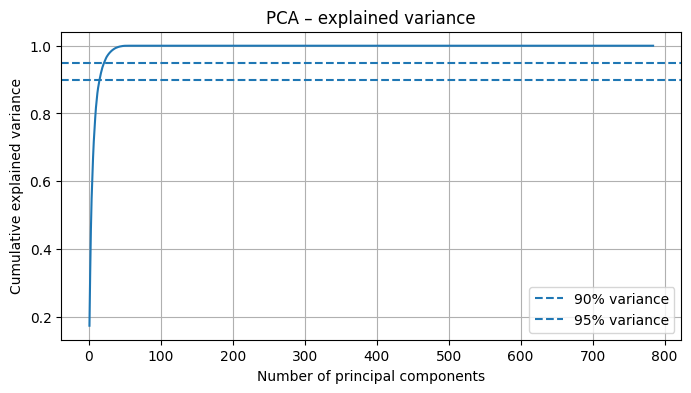

Components needed for 90% variance: 16


PCA output shape: (1797, 50)
Variance retained by selected components: 0.9998


In [6]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – explained variance")
plt.legend()
plt.grid(True)
plt.show()

n_components_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)
print("Components needed for 90% variance:", n_components_90)

PCA_COMPONENTS = min(50, X.shape[1], n_samples - 1)
pca = PCA(n_components=PCA_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("PCA output shape:", X_pca.shape)
print("Variance retained by selected components:", round(pca.explained_variance_ratio_.sum(), 4))

### 5.2 t-SNE – visualization

t-SNE is useful for visualizing high-dimensional data in 2D. It is mainly a visualization method, not the preferred representation for large-scale clustering.

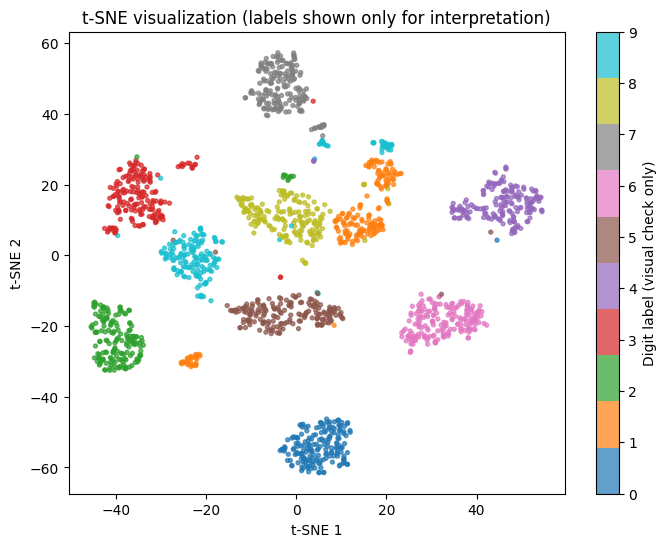

In [7]:
TSNE_SAMPLES = min(2000, n_samples)
tsne_idx = rng.choice(n_samples, size=TSNE_SAMPLES, replace=False)
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_pca[tsne_idx])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_eval[tsne_idx],
                      cmap="tab10", s=8, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label="Digit label (visual check only)")
plt.title("t-SNE visualization (labels shown only for interpretation)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

## 6. Clustering algorithms

We use PCA features. Each algorithm is fitted using `X_pca` only. The number of clusters is set to 10 because MNIST contains ten digit categories; this is a modelling choice, not use of the labels.

In [8]:
def safe_internal_scores(features, cluster_labels, name):
    cluster_labels = np.asarray(cluster_labels)
    valid = cluster_labels != -1  # DBSCAN noise excluded from metric calculations
    labels_valid = cluster_labels[valid]
    features_valid = features[valid]
    unique = np.unique(labels_valid)
    if len(unique) < 2 or len(unique) >= len(labels_valid):
        return {"Algorithm": name, "Silhouette": np.nan,
                "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan,
                "Clusters": len(unique), "Noise points": int(np.sum(~valid))}
    # Limit metric computation for speed on larger samples.
    metric_sample = min(2500, len(features_valid))
    return {
        "Algorithm": name,
        "Silhouette": silhouette_score(features_valid, labels_valid,
                                       sample_size=metric_sample, random_state=RANDOM_STATE),
        "Davies-Bouldin": davies_bouldin_score(features_valid, labels_valid),
        "Calinski-Harabasz": calinski_harabasz_score(features_valid, labels_valid),
        "Clusters": len(unique),
        "Noise points": int(np.sum(~valid))
    }

results = []
cluster_labels = {}

### 6.1 K-Means

In [9]:
start = time.time()
kmeans = KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_pca)
cluster_labels["K-Means"] = labels_kmeans
results.append(safe_internal_scores(X_pca, labels_kmeans, "K-Means"))
print("K-Means completed in", round(time.time() - start, 2), "seconds")
print("Inertia:", round(kmeans.inertia_, 2))

K-Means completed in 0.11 seconds
Inertia: 36020.16


### 6.2 Mini-Batch K-Means

A faster K-Means variant that updates cluster centers using small batches.

In [10]:
start = time.time()
mbk = MiniBatchKMeans(n_clusters=10, batch_size=256, n_init=10, random_state=RANDOM_STATE)
labels_mbk = mbk.fit_predict(X_pca)
cluster_labels["MiniBatch K-Means"] = labels_mbk
results.append(safe_internal_scores(X_pca, labels_mbk, "MiniBatch K-Means"))
print("MiniBatch K-Means completed in", round(time.time() - start, 2), "seconds")

MiniBatch K-Means completed in 0.15 seconds


### 6.3 Agglomerative Hierarchical Clustering

Builds a hierarchy of clusters by repeatedly merging similar observations. It can be computationally expensive, so this section uses a smaller sample.

In [11]:
AGG_SAMPLES = min(2500, n_samples)
agg_idx = rng.choice(n_samples, size=AGG_SAMPLES, replace=False)
start = time.time()
agg = AgglomerativeClustering(n_clusters=10, linkage="ward")
labels_agg_small = agg.fit_predict(X_pca[agg_idx])
cluster_labels["Agglomerative (sample)"] = labels_agg_small
results.append(safe_internal_scores(X_pca[agg_idx], labels_agg_small,
                                    "Agglomerative (sample)"))
print("Agglomerative clustering completed in", round(time.time() - start, 2), "seconds")

Agglomerative clustering completed in 0.14 seconds


### 6.4 DBSCAN

DBSCAN groups dense regions and marks isolated points as noise (`-1`). Results depend strongly on `eps` and `min_samples`; the values below are starting points after PCA.

In [12]:
DBSCAN_SAMPLES = min(2500, n_samples)
db_idx = rng.choice(n_samples, size=DBSCAN_SAMPLES, replace=False)
start = time.time()
dbscan = DBSCAN(eps=5.0, min_samples=8)
labels_dbscan = dbscan.fit_predict(X_pca[db_idx])
cluster_labels["DBSCAN (sample)"] = labels_dbscan
results.append(safe_internal_scores(X_pca[db_idx], labels_dbscan, "DBSCAN (sample)"))
print("DBSCAN completed in", round(time.time() - start, 2), "seconds")
print("DBSCAN cluster labels:", np.unique(labels_dbscan))

DBSCAN completed in 0.06 seconds
DBSCAN cluster labels: [-1  0]


### 6.5 Gaussian Mixture Model (GMM)

GMM assumes the data is generated from a mixture of Gaussian distributions and gives soft cluster probabilities.

In [13]:
GMM_SAMPLES = min(4000, n_samples)
gmm_idx = rng.choice(n_samples, size=GMM_SAMPLES, replace=False)
start = time.time()
gmm = GaussianMixture(n_components=10, covariance_type="diag",
                      reg_covar=1e-5, random_state=RANDOM_STATE, max_iter=100)
labels_gmm = gmm.fit_predict(X_pca[gmm_idx])
cluster_labels["Gaussian Mixture (sample)"] = labels_gmm
results.append(safe_internal_scores(X_pca[gmm_idx], labels_gmm,
                                    "Gaussian Mixture (sample)"))
print("GMM completed in", round(time.time() - start, 2), "seconds")
print("AIC:", round(gmm.aic(X_pca[gmm_idx]), 2))
print("BIC:", round(gmm.bic(X_pca[gmm_idx]), 2))

GMM completed in 0.12 seconds
AIC: 83002.64
BIC: 88545.96


## 7. Compare clustering results using internal metrics

These scores do not need the true digit labels:
- **Silhouette:** higher is generally better (range −1 to 1).
- **Davies–Bouldin:** lower is generally better.
- **Calinski–Harabasz:** higher is generally better.

In [14]:
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Clusters,Noise points
0,K-Means,0.2000,1.7874,201.0901,10,0
1,MiniBatch K-Means,0.2012,1.8236,197.2687,10,0
2,Agglomerative (sample),0.1942,1.7307,186.1087,10,0
3,DBSCAN (sample),NaN,NaN,NaN,1,3
4,Gaussian Mixture (sample),0.1661,1.8174,174.4181,10,0


## 8. Optional external evaluation (labels are used only here)

This section compares discovered clusters with the known digit labels. It does **not** train or tune the clustering models. Cluster IDs are arbitrary, so direct accuracy is not appropriate; Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) are used.

In [15]:
external_rows = []

def add_external(name, idx, pred):
    external_rows.append({
        "Algorithm": name,
        "Adjusted Rand Index": adjusted_rand_score(y_eval[idx], pred),
        "Normalized Mutual Information": normalized_mutual_info_score(y_eval[idx], pred)
    })

all_idx = np.arange(n_samples)
add_external("K-Means", all_idx, labels_kmeans)
add_external("MiniBatch K-Means", all_idx, labels_mbk)
add_external("Agglomerative (sample)", agg_idx, labels_agg_small)
add_external("DBSCAN (sample)", db_idx, labels_dbscan)
add_external("Gaussian Mixture (sample)", gmm_idx, labels_gmm)

external_df = pd.DataFrame(external_rows)
display(external_df.round(4))

,Algorithm,Adjusted Rand Index,Normalized Mutual Information
0,K-Means,0.6668,0.7444
1,MiniBatch K-Means,0.6223,0.7213
2,Agglomerative (sample),0.7277,0.8387
3,DBSCAN (sample),0.0000,0.0024
4,Gaussian Mixture (sample),0.5624,0.7002


## 9. Visualize K-Means clusters

We visualize the first two PCA dimensions. The cluster colors represent K-Means assignments, not the actual digit labels.

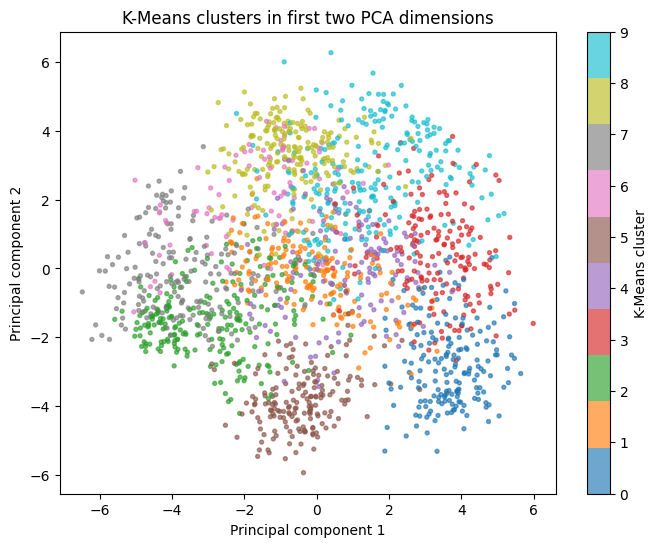

In [16]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_kmeans, cmap="tab10",
                 s=8, alpha=0.65)
plt.colorbar(sc, label="K-Means cluster")
plt.title("K-Means clusters in first two PCA dimensions")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.show()

## 10. Anomaly detection

Anomaly detection is another unsupervised task. We use Isolation Forest and Local Outlier Factor (LOF) to identify unusual images. These methods do not use digit labels.

In [17]:
start = time.time()
iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE, n_estimators=150)
iso_pred = iso.fit_predict(X_pca)  # 1 = inlier, -1 = anomaly
print("Isolation Forest anomalies:", int(np.sum(iso_pred == -1)),
      "out of", len(iso_pred))
print("Completed in", round(time.time() - start, 2), "seconds")

start = time.time()
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
lof_pred = lof.fit_predict(X_pca)
print("LOF anomalies:", int(np.sum(lof_pred == -1)),
      "out of", len(lof_pred))
print("Completed in", round(time.time() - start, 2), "seconds")

Isolation Forest anomalies: 36 out of 1797
Completed in 0.17 seconds
LOF anomalies: 36 out of 1797
Completed in 0.02 seconds


### Display some Isolation Forest anomalies

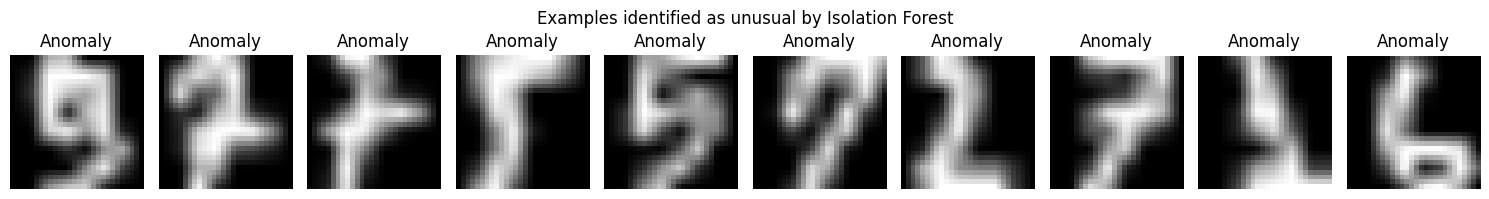

In [18]:
anomaly_idx = np.where(iso_pred == -1)[0][:10]
fig, axes = plt.subplots(1, max(1, len(anomaly_idx)), figsize=(15, 2))
if len(anomaly_idx) == 1:
    axes = [axes]
for ax, idx in zip(axes, anomaly_idx):
    ax.imshow(images[sample_idx[idx]], cmap="gray")
    ax.set_title("Anomaly")
    ax.axis("off")
plt.suptitle("Examples identified as unusual by Isolation Forest")
plt.tight_layout()
plt.show()

## 11. Save results

The following files are saved beside the notebook:
- `mnist_clustering_internal_metrics.csv`
- `mnist_clustering_external_metrics.csv`
- `mnist_kmeans_assignments.csv`

In [19]:
results_df.to_csv("mnist_clustering_internal_metrics.csv", index=False)
external_df.to_csv("mnist_clustering_external_metrics.csv", index=False)
pd.DataFrame({
    "sample_original_index": sample_idx,
    "kmeans_cluster": labels_kmeans,
    "actual_label_for_evaluation_only": y_eval
}).to_csv("mnist_kmeans_assignments.csv", index=False)
print("CSV result files saved.")

CSV result files saved.


## 12. Conclusion

1. PCA reduced the original pixel feature space while retaining useful variance.
2. t-SNE helped visualize the structure of handwritten digits in two dimensions.
3. K-Means and Mini-Batch K-Means partitioned the images into ten clusters.
4. Agglomerative clustering built hierarchical groups; DBSCAN identified dense groups and noise; GMM modelled probabilistic clusters.
5. Silhouette, Davies–Bouldin, and Calinski–Harabasz evaluated cluster structure without labels.
6. ARI and NMI optionally compared clusters with known digit labels after training.
7. Isolation Forest and LOF identified unusual images.

**Important limitation:** Unsupervised clusters do not automatically correspond one-to-one with digit classes. Similar-looking digits can be grouped together, and a single digit class can be split across multiple clusters. Results also depend on sample size, PCA dimensions, and algorithm parameters.

### Viva questions
- **Why is MNIST suitable?** It contains many handwritten digit images with high-dimensional pixel features.
- **Why not use labels during clustering?** Clustering is unsupervised; labels are reserved for post-training evaluation.
- **Why use PCA?** To reduce dimensions, remove some redundancy, and speed up clustering.
- **Why can DBSCAN return noise points?** Points in low-density regions may not belong to any dense cluster.
- **Which metric is label-independent?** Silhouette, Davies–Bouldin, and Calinski–Harabasz.
- **Why use ARI/NMI?** They compare cluster assignments with known classes without assuming cluster IDs equal digit IDs.